# 12. Forward in time, places not seen, and the checks

Notebook 11 left one year out at a time and found that the satellite signals account for about a quarter of the decline of clipped biomass. This notebook puts the same models through the other tests that docs/design.md set before any model was fitted:

- **Forward in time.** Fitted to 2011–2015 and applied to 2016–2020, as a model built in 2015 would have been used.
- **Places not seen.** One aimag left out at a time, with nothing taken as a departure, so the model has to place sites it has never seen.
- **The checks.** The ladder without 2020, and with the years from 2007.

- **Reads** `model_site_years.csv` and `sites.csv` from `data/processed/`.
- **Writes** nothing.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mn_desertification import model, paths, trends
from mn_desertification.rules import MAIN_YEARS

table = pd.read_csv(paths.PROCESSED_DIR / "model_site_years.csv")
decade = table[table["year"].between(*MAIN_YEARS)]
print("Site-years 2011-2020:", len(decade), "| in 2011-2015:", (decade["year"] <= 2015).sum(), "| in 2016-2020:", (decade["year"] >= 2016).sum())
print("Aimags:", decade["aimag"].nunique(), "| sites per aimag:", decade.groupby("aimag")["gid"].nunique().min(), "to",
      decade.groupby("aimag")["gid"].nunique().max())

Site-years 2011-2020: 13367 | in 2011-2015: 6442 | in 2016-2020: 6925
Aimags: 22 | sites per aimag: 4 to 119


## Forward in time

Each model is fitted to 2011–2015, with each site's averages taken over those five years, and estimates 2016–2020. `mean departure` is how far the later years were from those averages in the field, `mean estimate` is what the model expected, and `mean left unexplained` is the gap between the two.

In [2]:
# Forward in time: fitted to 2011-2015, applied to 2016-2020
forward_rows, forward_by = [], {}
for rung in model.RUNGS:
    for kind in ["line", "trees"]:
        result = model.forward(decade, model.predictors_up_to(rung), kind, last_fit_year=2015)
        forward_by[(rung, kind)] = result
        forward_rows.append({"rung": rung, "model": kind, "site-years": len(result),
                             "mean departure": round(result["departure"].mean(), 3),
                             "mean estimate": round(result["estimate"].mean(), 3),
                             "mean left unexplained": round(result["remainder"].mean(), 3),
                             "skill": round(model.skill(result), 3)})
pd.DataFrame(forward_rows)

,rung,model,site-years,mean departure,mean estimate,mean left unexplained,skill
0,1 weather,line,6867,-0.129,-0.066,-0.063,0.116
1,1 weather,trees,6867,-0.129,-0.071,-0.058,0.092
2,2 greenness,line,6867,-0.129,-0.059,-0.070,0.245
3,2 greenness,trees,6867,-0.129,-0.079,-0.050,0.236
4,3 all bands,line,6867,-0.129,-0.060,-0.069,0.237
5,3 all bands,trees,6867,-0.129,-0.071,-0.058,0.238
6,4 the season,line,6867,-0.129,-0.073,-0.056,0.188
7,4 the season,trees,6867,-0.129,-0.064,-0.065,0.213
8,5 herds,line,6867,-0.129,-0.139,0.010,0.223
9,5 herds,trees,6867,-0.129,-0.116,-0.013,0.277


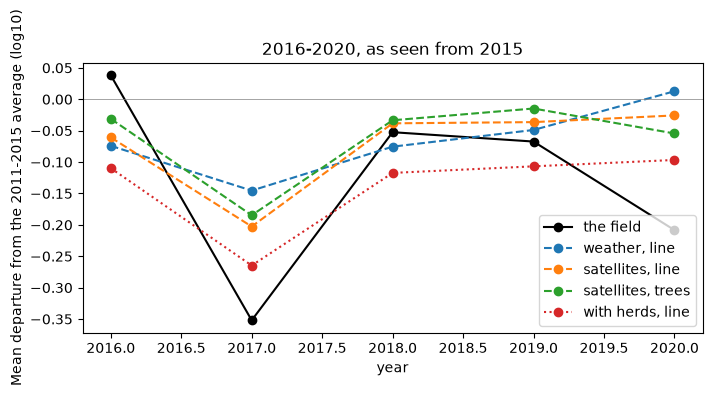

year,2016,2017,2018,2019,2020
the field,0.038,-0.352,-0.052,-0.067,-0.208
"weather, line",-0.074,-0.145,-0.075,-0.049,0.013
"satellites, line",-0.061,-0.203,-0.038,-0.036,-0.026
"satellites, trees",-0.031,-0.185,-0.033,-0.015,-0.054
"with herds, line",-0.110,-0.265,-0.117,-0.107,-0.097


In [3]:
# The five later years one by one: what the field found, and what three of the models expected
by_year = pd.DataFrame({"the field": forward_by[("1 weather", "line")].groupby("year")["departure"].mean()})
for label, key in [("weather, line", ("1 weather", "line")), ("satellites, line", ("4 the season", "line")),
                   ("satellites, trees", ("4 the season", "trees")), ("with herds, line", ("5 herds", "line"))]:
    by_year[label] = forward_by[key].groupby("year")["estimate"].mean()

ax = by_year.plot(marker="o", figsize=(8, 3.5), style=["k-", "--", "--", "--", ":"])
ax.axhline(0, color="grey", linewidth=0.5)
ax.set_ylabel("Mean departure from the 2011-2015 average (log10)")
ax.set_title("2016-2020, as seen from 2015")
plt.show()
by_year.round(3).T

- **The later years were 0.129 lower,** in log10, about a quarter less biomass than in 2011–2015. The weather alone expected about half of that.
- **The satellites raise the skill but do not narrow the gap.** At every satellite rung −0.05 to −0.07 is left unexplained, as with the weather alone.
- **The models miss the depth of the two bad years.** In 2017 the field is at −0.352 and the satellite models at about −0.19. In 2020 the field is at −0.208 and they are at −0.03 to −0.05. In 2018 and 2019 they are about right.
- **The herds close the gap as a clock would** (notebook 11): their rise over 2011–2015 simply continues.

## Places not seen

One aimag is left out at a time and each model is fitted to the other 21. The biomass and the predictors enter as they are. `skill, site-years` is the share of all the differences in biomass that the estimates explain, and `skill, sites` the same for the sites' ten-year averages. `typical error` is how far off the middle estimate is.

In [4]:
# Places not seen: one aimag left out at a time, with nothing taken as a departure. About two minutes.
place_rows, placed_by = [], {}
for rung in model.RUNGS:
    for kind in ["line", "trees"]:
        result = model.leave_group_out(decade, model.predictors_up_to(rung), kind)
        placed_by[(rung, kind)] = result
        place_rows.append({"rung": rung, "model": kind,
                           "skill, site-years": round(model.level_skill(result), 3),
                           "skill, sites": round(model.level_skill(result, by_site=True), 3),
                           "typical error": f"{10 ** result['remainder'].abs().median() - 1:.0%}"})
places = pd.DataFrame(place_rows)
places

,rung,model,"skill, site-years","skill, sites",typical error
0,1 weather,line,0.234,0.481,89%
1,1 weather,trees,0.205,0.448,91%
2,2 greenness,line,0.317,0.528,81%
3,2 greenness,trees,0.320,0.548,81%
4,3 all bands,line,0.341,0.544,78%
5,3 all bands,trees,0.335,0.544,78%
6,4 the season,line,0.339,0.572,77%
7,4 the season,trees,0.357,0.570,76%
8,5 herds,line,0.349,0.557,76%
9,5 herds,trees,0.373,0.572,76%


In [5]:
# How even is it? The best model's score in each aimag left out, and what it leaves unexplained year by year
best = placed_by[("4 the season", "trees")]
names = pd.read_csv(paths.PROCESSED_DIR / "sites.csv").assign(aimag=lambda sites: sites["asid"] // 100).groupby("aimag")["aimag_eng"].first()
per_aimag = pd.DataFrame({"aimag": names, "sites": best.groupby("aimag")["gid"].nunique(),
                          "skill": best.groupby("aimag").apply(model.level_skill, include_groups=False).round(2),
                          "mean left unexplained": best.groupby("aimag")["remainder"].mean().round(2)})
print("Aimags with a skill above 0.3:", (per_aimag["skill"] > 0.3).sum(), "of", len(per_aimag), "| below zero:", (per_aimag["skill"] < 0).sum())
trend, low, high = trends.mean_trend(best)
print(f"Trend of what it leaves unexplained, 2011-2020: {trend:.3f} per decade (95% range {low:+.3f} to {high:+.3f})")
per_aimag.sort_values("skill", ascending=False).set_index("aimag").T

Aimags with a skill above 0.3: 1 of 22 | below zero: 5
Trend of what it leaves unexplained, 2011-2020: -0.194 per decade (95% range -0.306 to -0.082)


aimag,Darkhan-Uul,Tuv,Bayankhongor,Uvurkhangai,Arkhangai,Sukhbaatar,Khentii,Dundgovi,Khuvsgul,Zavkhan,...,Govi-Altai,Selenge,Khovd,Dornogovi,Uvs,Bulgan,Ulaanbaatar,Bayan-Ulgii,Govisumber,Dornod
sites,9.00,95.00,94.00,102.00,98.00,58.00,80.00,66.00,119.00,114.00,...,76.00,45.00,83.00,66.00,88.00,75.00,10.00,77.00,10.00,54.00
skill,0.43,0.29,0.29,0.24,0.21,0.18,0.18,0.15,0.10,0.10,...,0.07,0.06,0.04,0.04,0.02,-0.01,-0.05,-0.13,-0.18,-0.31
mean left unexplained,-0.00,0.09,-0.12,-0.10,-0.07,0.01,0.03,0.09,0.08,0.13,...,-0.03,0.14,-0.07,-0.05,-0.02,-0.21,-0.04,0.11,0.01,0.22


- **A site's average biomass can be placed fairly well.** The models explain a little over half of the differences between sites' averages.
- **A site-year is harder,** at about a third, and the typical estimate is off by a factor of nearly 1.8.
- **Within an aimag the model tells little apart.** Its skill there is above 0.3 in one aimag of 22 and below zero in five. Its overall score comes from telling regions apart.
- **The decline shows here too.** What the best model leaves unexplained falls by −0.194 log10 per decade, although it saw the same years in other aimags.

## The checks

The ladder of notebook 11 at three rungs, twice: without 2020, and with every year from 2007 left out in turn. The share of the trend removed is against the first row of each block, the weather with the line.

In [6]:
# The checks: the ladder without 2020, and with the years from 2007
def short_ladder(rows, period):
    """Leave one year out for three rungs, with the trend taken over ``period``."""
    out = []
    for rung in ["1 weather", "4 the season", "5 herds"]:
        for kind in ["line", "trees"]:
            result = model.leave_year_out(rows, model.predictors_up_to(rung), kind)
            trend, low, high = trends.mean_trend(result[result["year"].between(*period)])
            out.append({"rung": rung, "model": kind, "skill": round(model.skill(result), 3),
                        "trend left": round(trend, 3), "95% range": f"{low:+.3f} to {high:+.3f}"})
    out = pd.DataFrame(out)
    out["share of the trend removed"] = (1 - out["trend left"] / out["trend left"].iloc[0]).map("{:.0%}".format)
    return out

checks = pd.concat({"2011-2019, without 2020": short_ladder(decade[decade["year"] < 2020], (2011, 2019)),
                    "2007-2020, trend over 2011-2020": short_ladder(table, MAIN_YEARS)})
checks

rung  model  skill  trend left  \
2011-2019, without 2020         0     1 weather   line  0.085      -0.116   
                                1     1 weather  trees  0.073      -0.165   
                                2  4 the season   line  0.159      -0.114   
                                3  4 the season  trees  0.167      -0.147   
                                4       5 herds   line  0.175       0.010   
                                5       5 herds  trees  0.183      -0.029   
2007-2020, trend over 2011-2020 0     1 weather   line  0.097      -0.270   
                                1     1 weather  trees  0.101      -0.262   
                                2  4 the season   line  0.190      -0.231   
                                3  4 the season  trees  0.199      -0.218   
                                4       5 herds   line  0.202      -0.123   
                                5       5 herds  trees  0.201      -0.151   

                                          95% range share of the trend removed  
2011-2019, without 2020         0  -0.440 to +0.208                         0%  
                                1  -0.438 to +0.108                       -42%  
                                2  -0.299 to +0.071                         2%  
                                3  -0.310 to +0.015                       -27%  
                                4  -0.166 to +0.185                       109%  
                                5  -0.184 to +0.127                        75%  
2007-2020, trend over 2011-2020 0  -0.476 to -0.065                         0%  
                                1  -0.421 to -0.104                         3%  
                                2  -0.353 to -0.109                        14%  
                                3  -0.308 to -0.129                        19%  
                                4  -0.259 to +0.012                        54%  
                                5  -0.236 to -0.067                        44%

- **Without 2020 the decline itself is uncertain.** The reference trend halves and its range includes zero, as notebook 3 found. The satellites remove none of it.
- **With the years from 2007 the result of notebook 11 holds.** The satellites remove 14% to 19% of the trend.
- **The herds no longer act as a clock.** Over 2007–2020 they are not a steady rise, because the dzud of 2010 cut them, and they remove about half of the trend where they removed 83% to 94% before.

## In short

- **A model built in 2015 would have expected lower biomass after it, but only half as much lower as the field found.** The gap sits in the two bad years, 2017 and 2020.
- **At places not seen, the models place a site's average biomass fairly well and a single year poorly.**
- **The result of notebook 11 holds in both checks.**